In [11]:
from machinelearningproject_ct4101.utils import load_splits
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 1337


splits_path = "../../../data/processed/"

### Baseline models.
1. Dummy Classifiers using most frequent
    - predict the most frequent class label in $y$
    - Our model predicts false 100% of the time


In [12]:
X_train, X_test, X_val, y_train, y_test, y_val = load_splits(splits_path)

- We call 85% of our customers didn't purchase anything, so our model, which predicts false 100% of the time can obtain 85% accuracy without actually learning anything useful about the data
- This demonstrates that accuracy alone is misleading for our imbalanced dataset
- Our goal is to outpreform this baseline in recall, precision and f1 for the True class

Accuracy: 0.8454054054054054
              precision    recall  f1-score   support

       False       0.85      1.00      0.92      1564
        True       0.00      0.00      0.00       286

    accuracy                           0.85      1850
   macro avg       0.42      0.50      0.46      1850
weighted avg       0.71      0.85      0.77      1850



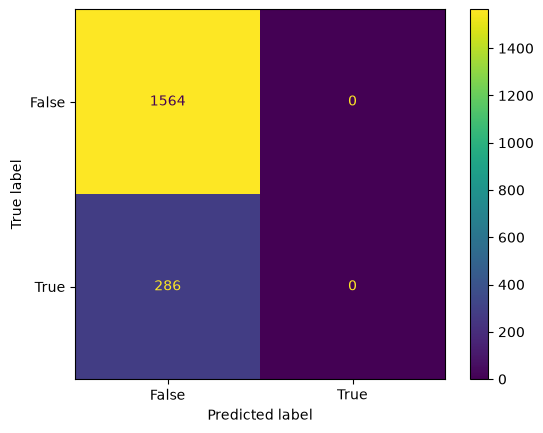

In [14]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_estimator(dummy, X_val, y_val)
plt.show()